# UC pay by department

Compare `gross_pay` (total pay excluding benefits) in `cleaned_salaries (1).parquet`.

In [1]:
from pathlib import Path
import math
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display

PAY_COL = "gross_pay"  # Total pay: base + overtime + other (rounding differences possible)
YEAR = None  # None pools all years; set to 2024 for a single-year comparison
MIN_PAY = 40_000
MIN_OBSERVATIONS = 10
TOP_N = 10
HISTOGRAMS_PER_PAGE = 24
INVALID_DEPARTMENT_LABELS = {"index.php"}

# Works from this folder, its subfolders, or the repository root.
candidates = [
    parent / relative
    for parent in (Path.cwd(), *Path.cwd().parents)
    for relative in ("Data/cleaned_salaries (1).parquet",
                     "CSC4693/Faculty/Data/cleaned_salaries (1).parquet")
]
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Could not locate Data/cleaned_salaries (1).parquet")
raw = pd.read_parquet(data_path)
pay_labels = {"gross_pay": "Total pay (excluding benefits)", "base_pay": "Base pay"}
pay_label = pay_labels.get(PAY_COL, PAY_COL)
print(f"Loaded {len(raw):,} payroll rows from {data_path.name}")


Loaded 246,331 payroll rows from cleaned_salaries (1).parquet


In [2]:
df = raw.drop_duplicates().copy()
exact_duplicates_removed = len(raw) - len(df)
if YEAR is not None:
    df = df.loc[df["year"].eq(YEAR)].copy()
df["department"] = (df["department"].astype("string")
                    .str.replace(r"\s+", " ", regex=True).str.strip())
df["pay"] = pd.to_numeric(df[PAY_COL], errors="coerce")
valid_department = (
    df["department"].notna()
    & df["department"].ne("")
    & ~df["department"].str.casefold().isin(INVALID_DEPARTMENT_LABELS)
).fillna(False)
valid_pay = df["pay"].notna() & np.isfinite(df["pay"])
valid_pay &= df["pay"].ge(MIN_PAY)
clean = df.loc[valid_department & valid_pay].copy()

summary = (clean.groupby("department")["pay"]
           .agg(n="count", median_pay="median", mean_pay="mean",
                min_pay="min", max_pay="max")
           .query("n >= @MIN_OBSERVATIONS")
           .sort_values(["median_pay", "mean_pay"], ascending=False))
plot_data = clean.loc[clean["department"].isin(summary.index)].copy()
if summary.empty:
    raise ValueError("No departments meet the selected filters.")
year_values = sorted(plot_data["year"].unique())
years = str(year_values[0]) if len(year_values) == 1 else f"{year_values[0]}-{year_values[-1]} (pooled)"
pay_filter_note = f"Pay >= ${MIN_PAY:,.0f}"
print(f"Payroll year(s): {years}; {pay_label}; {pay_filter_note}")
print(f"Removed {exact_duplicates_removed:,} fully identical payroll rows.")
print(f"Excluded {int((~valid_department).sum()):,} missing/invalid department rows.")
print(f"Excluded {int((valid_department & ~valid_pay).sum()):,} further rows by pay filter.")
print(f"Eligible: {len(summary):,} departments, {len(plot_data):,} observations "
      f"(minimum {MIN_OBSERVATIONS} per department).")
print(f"Threshold excludes {len(clean) - len(plot_data):,} further observations.")


Payroll year(s): 2013-2024 (pooled); Total pay (excluding benefits); Pay >= $40,000
Removed 498 fully identical payroll rows.
Excluded 0 missing/invalid department rows.
Excluded 3,097 further rows by pay filter.
Eligible: 10 departments, 242,736 observations (minimum 10 per department).
Threshold excludes 0 further observations.


## Highest and lowest median pay

Sample sizes count the observations used in both the rankings and histograms.
The complete ranking is available as `summary` (highest median first).


Highest 10 departments by median pay


,department,n,median_pay,mean_pay,min_pay,max_pay
0,Medicine & Health Sciences,111301,"$227,850.00","$270,016.64","$40,000.00","$3,974,061.00"
1,"Business, Economics & Finance",9497,"$211,137.00","$232,386.63","$40,000.00","$778,101.00"
2,Engineering,12607,"$162,126.00","$177,223.34","$40,000.00","$744,549.00"
3,Education & Public Administration,7770,"$159,538.50","$187,684.33","$40,000.00","$677,222.00"
4,Science & Mathematics,34099,"$158,167.00","$173,068.57","$40,000.00","$981,238.00"
5,Computer Science,8921,"$152,550.00","$163,662.72","$40,000.00","$704,654.00"
6,"Agriculture, Food & Animal",1846,"$142,015.50","$156,023.93","$40,142.00","$591,242.00"
7,Social Sciences & Communication,17293,"$134,658.00","$150,063.28","$40,000.00","$592,567.00"
8,Architecture & Environmental Design,2438,"$130,487.50","$141,300.44","$40,000.00","$585,517.00"
9,Humanities & Languages,36964,"$108,800.00","$122,473.31","$40,000.00","$740,580.00"


Lowest 10 departments by median pay


,department,n,median_pay,mean_pay,min_pay,max_pay
0,Humanities & Languages,36964,"$108,800.00","$122,473.31","$40,000.00","$740,580.00"
1,Architecture & Environmental Design,2438,"$130,487.50","$141,300.44","$40,000.00","$585,517.00"
2,Social Sciences & Communication,17293,"$134,658.00","$150,063.28","$40,000.00","$592,567.00"
3,"Agriculture, Food & Animal",1846,"$142,015.50","$156,023.93","$40,142.00","$591,242.00"
4,Computer Science,8921,"$152,550.00","$163,662.72","$40,000.00","$704,654.00"
5,Science & Mathematics,34099,"$158,167.00","$173,068.57","$40,000.00","$981,238.00"
6,Education & Public Administration,7770,"$159,538.50","$187,684.33","$40,000.00","$677,222.00"
7,Engineering,12607,"$162,126.00","$177,223.34","$40,000.00","$744,549.00"
8,"Business, Economics & Finance",9497,"$211,137.00","$232,386.63","$40,000.00","$778,101.00"
9,Medicine & Health Sciences,111301,"$227,850.00","$270,016.64","$40,000.00","$3,974,061.00"


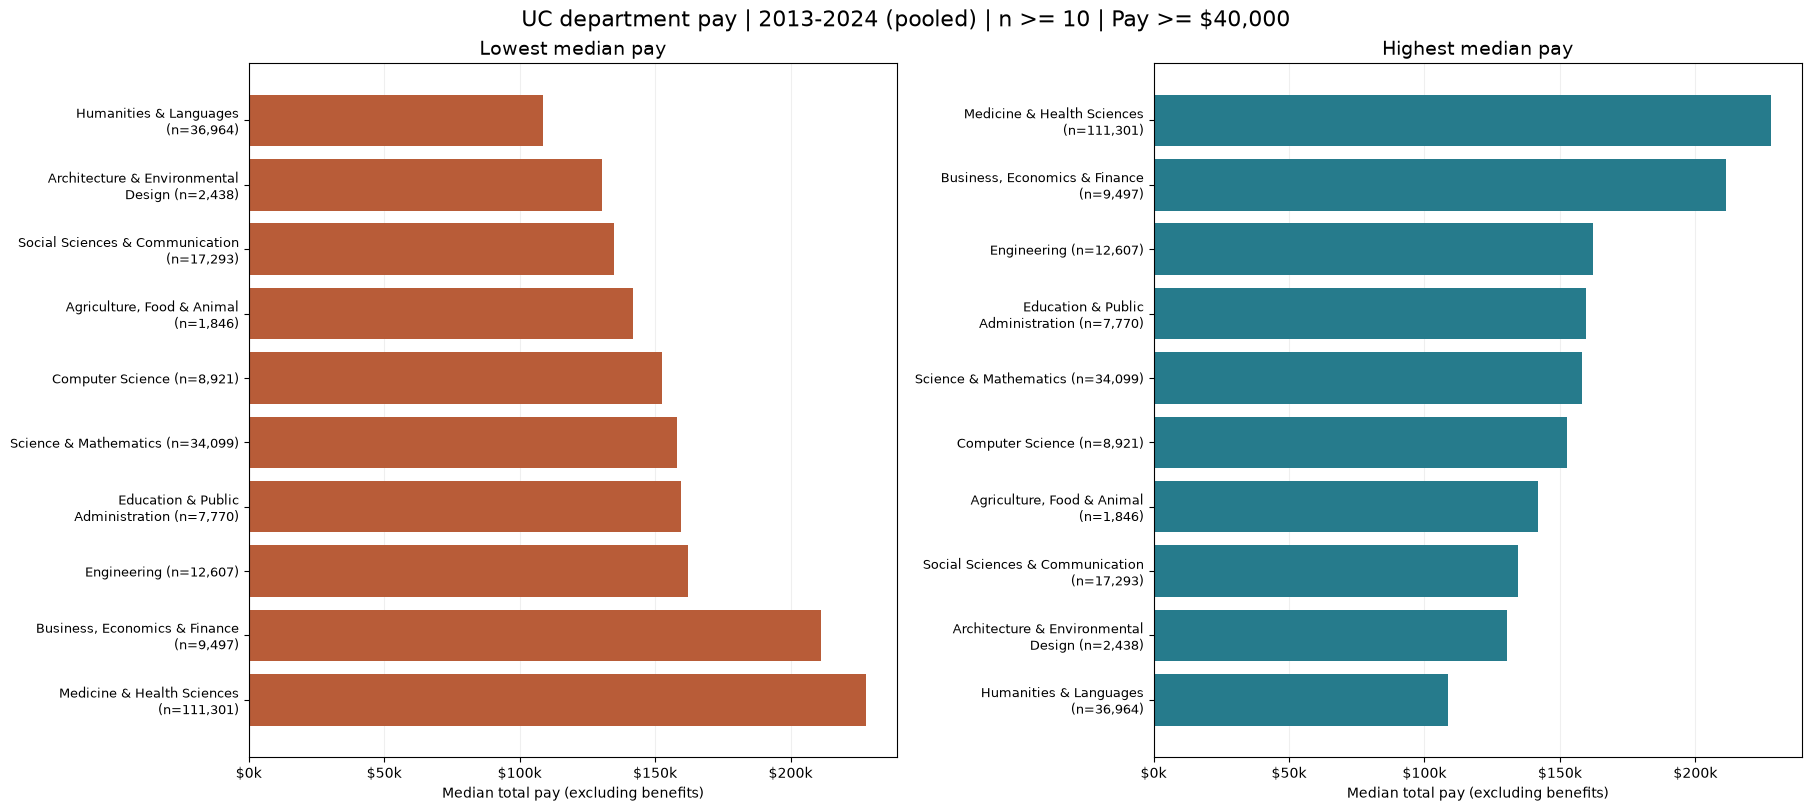

In [3]:
def show_pay_table(table):
    formatted = table.reset_index().copy()
    for column in ["median_pay", "mean_pay", "min_pay", "max_pay"]:
        formatted[column] = formatted[column].map(lambda value: f"${value:,.2f}")
    display(formatted)

print(f"Highest {min(TOP_N, len(summary))} departments by median pay")
show_pay_table(summary.head(TOP_N))
print(f"Lowest {min(TOP_N, len(summary))} departments by median pay")
show_pay_table(summary.sort_values(["median_pay", "mean_pay"]).head(TOP_N))

fig, axes = plt.subplots(1, 2, figsize=(18, 8), layout="constrained", sharex=True)
for ax, table, title, color in [
    (axes[0], summary.sort_values(["median_pay", "mean_pay"]).head(TOP_N),
     "Lowest median pay", "#b85c38"),
    (axes[1], summary.head(TOP_N), "Highest median pay", "#267b8c"),
]:
    labels = [textwrap.fill(f"{name} (n={row.n:,.0f})", 32)
              for name, row in table.iterrows()]
    ax.barh(range(len(table)), table["median_pay"], color=color)
    ax.set_yticks(range(len(table)), labels, fontsize=9)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(f"Median {pay_label.lower()}")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"${value / 1000:,.0f}k"))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle(f"UC department pay | {years} | n >= {MIN_OBSERVATIONS} | {pay_filter_note}", fontsize=16)
plt.show()


## Pay histograms for every eligible department

Panels run from highest to lowest median. Dashed lines mark medians. All panels use
common logarithmically spaced dollar bins and the same logarithmic x-axis; tick labels
show actual dollars. This keeps typical pay readable while retaining the full high-pay tail.
Equal horizontal distances represent equal pay ratios. Y-axes show observation counts
and vary by department. The complete ranking is available in `summary`.


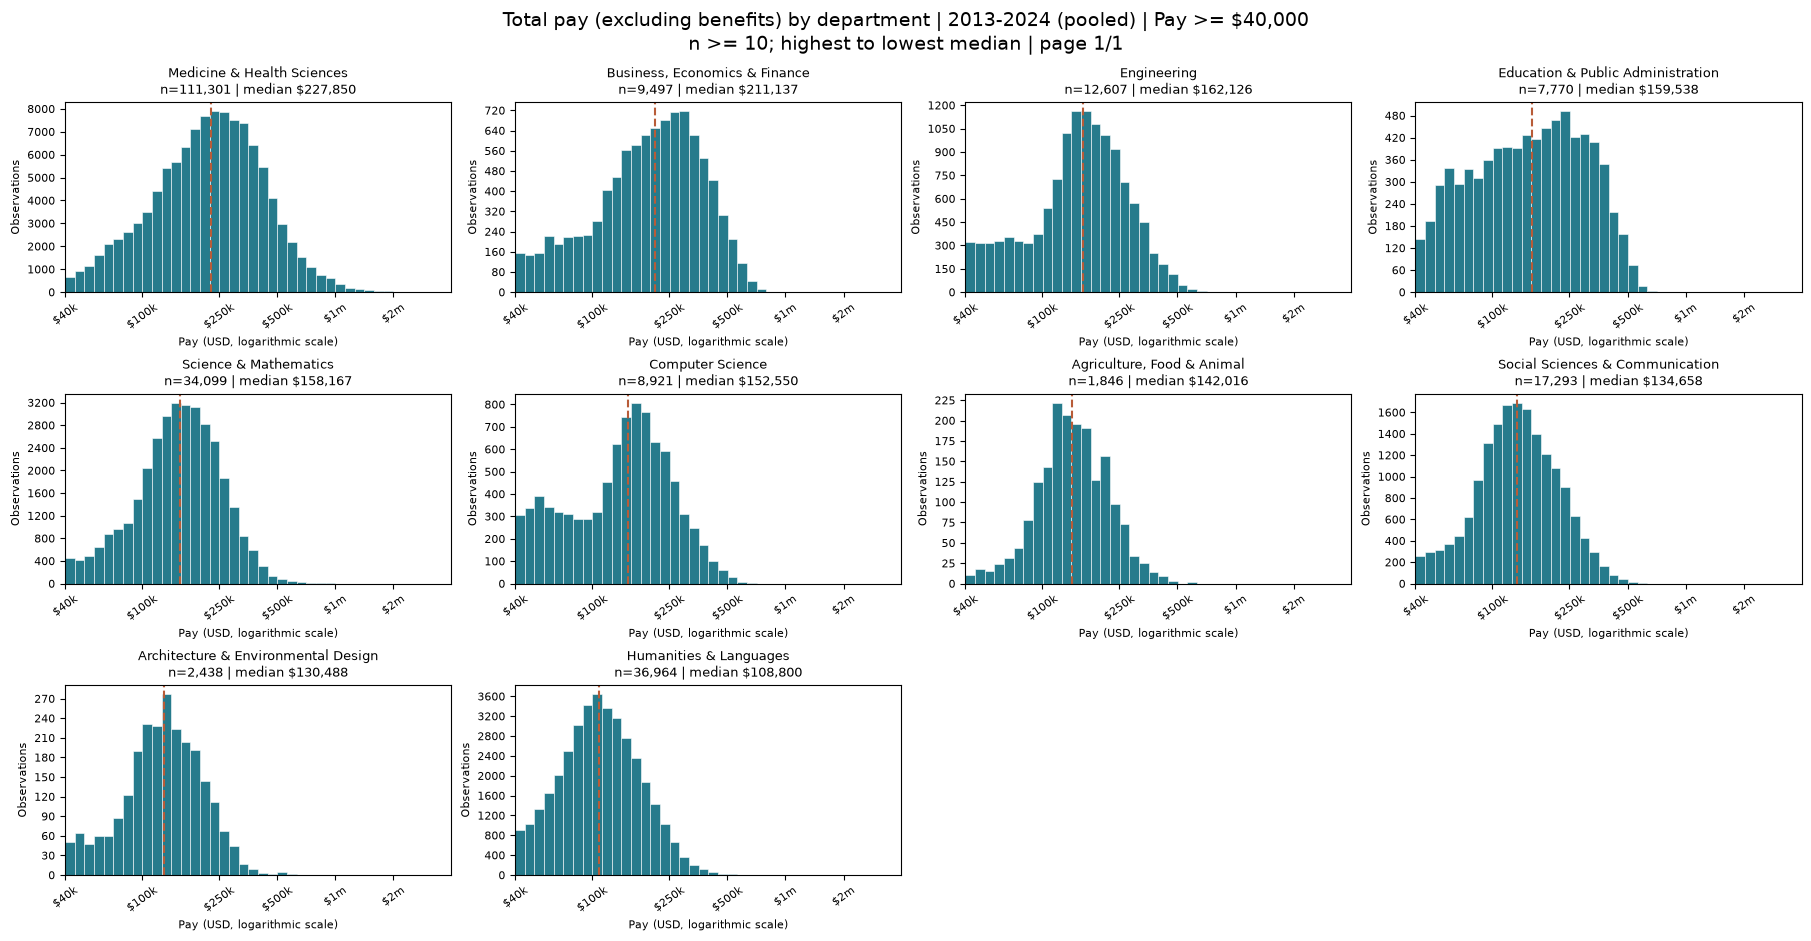

In [4]:
# Common bins make distributions comparable across departments.
upper_pay = float(plot_data["pay"].max())
bin_edges = np.geomspace(MIN_PAY, max(upper_pay, MIN_PAY + 1), 41)
pay_ticks = [v for v in [40_000, 100_000, 250_000, 500_000, 1_000_000, 2_000_000, 4_000_000]
             if MIN_PAY <= v <= upper_pay]
def pay_tick_label(value, pos):
    return f"${value / 1_000_000:g}m" if value >= 1_000_000 else f"${value / 1000:g}k"
departments = summary.index.tolist()
pages = math.ceil(len(departments) / HISTOGRAMS_PER_PAGE)

for start in range(0, len(departments), HISTOGRAMS_PER_PAGE):
    page_departments = departments[start:start + HISTOGRAMS_PER_PAGE]
    rows = math.ceil(len(page_departments) / 4)
    fig, axes = plt.subplots(rows, 4, figsize=(18, rows * 3.1),
                             squeeze=False, sharex=True, layout="constrained")
    for ax, department in zip(axes.flat, page_departments):
        values = plot_data.loc[plot_data["department"].eq(department), "pay"]
        median = summary.loc[department, "median_pay"]
        ax.hist(values, bins=bin_edges, color="#267b8c", edgecolor="white", linewidth=0.4)
        ax.axvline(median, color="#b85c38", linestyle="--", linewidth=1.5)
        ax.set_title(textwrap.fill(department, 35)
                     + f"\nn={len(values):,} | median ${median:,.0f}", fontsize=9)
        ax.set_xlim(bin_edges[0], bin_edges[-1])
        ax.set_xlabel("Pay (USD, logarithmic scale)", fontsize=8)
        ax.set_ylabel("Observations", fontsize=8)
        ax.set_xscale("log")
        ax.set_xticks(pay_ticks)
        ax.minorticks_off()
        ax.xaxis.set_major_formatter(FuncFormatter(pay_tick_label))
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(labelsize=8, labelbottom=True)
        ax.tick_params(axis="x", labelrotation=35)
    for ax in list(axes.flat)[len(page_departments):]:
        ax.set_visible(False)
    page = start // HISTOGRAMS_PER_PAGE + 1
    fig.suptitle(f"{pay_label} by department | {years} | {pay_filter_note}\n"
                 f"n >= {MIN_OBSERVATIONS}; highest to lowest median | page {page}/{pages}", fontsize=14)
    plt.show()
